## Introducción al proyecto: Predicción de al demanda de taxis para Sweet Lift Taxi medinate series temporales.

La empresa Sweet Lift Taxi quiere predecir la cantidad de pedidos de taxi para la próxima hora, para saber cuántos conductores necesita en los aeropuertos.

## Descripción del problema:

La empresa Sweet Lift Taxi ha recopilado datos históricos sobre los pedidos de taxis en los aeropuertos. Con el objetivo de mejorar la disponibilidad de conductores durante las horas de mayor demanda, la empresa necesita anticipar cuántos pedidos de taxi se realizarán en la próxima hora. Contar con esta predicción permite a Sweet Lift Taxi planificar con antelación la asignación de conductores, reducir los tiempos de espera de los pasajeros y optimizar sus recursos operativos durante los picos de demanda.

## Objetivo del proyecto:

Este proyecto tiene como objetivo construir un modelo de machine learning capaz de predecir la cantidad de pedidos de taxis para la siguiente hora, a partir del análisis de una serie temporal histórica de pedidos.

## Metricas de evaluacion:

Para medir el desempeño del modelo se utilizará la métrica RECM (Raíz del Error Cuadrático Medio, o RMSE por sus siglas en inglés). Esta métrica penaliza en mayor medida los errores grandes, lo cual es adecuado en un contexto operativo donde las desviaciones importantes en la predicción de demanda pueden generar una mala planificación de recursos.

El objetivo del proyecto es lograr un valor de RECM en el conjunto de prueba que no supere el umbral de 48, este valor será el criterio principal para determinar si el modelo es apto para ser utilizado en producción.

## Datos disponibles:

Los datos utilizados en este proyecto provienen del archivo `taxi.csv`, el cual contiene el registro histórico del número de pedidos de taxi (columna num_orders) a lo largo del tiempo.
- `datetime`: fecha y hora de pedido
- `num_orders`: número de pedidos

## Metodología:
1. Remuestreo de los datos originales en intervalos de una hora, de manera que cada punto de la serie temporal represente el total de pedidos ocurridos en ese periodo.
2. Análisis exploratorio de la serie temporal, con el fin de identificar tendencias, estacionalidad y patrones relevantes en el comportamiento de la demanda.
3. Ingeniería de características, generando variables como valores rezagados (lags), medias móviles, y componentes temporales (hora, día de la semana, etc.) que permitan capturar la dinámica de la serie.
4. División de los datos en conjuntos de entrenamiento y prueba, reservando el 10% final de la serie temporal como conjunto de prueba, respetando el orden cronológico de los datos.
5. Entrenamiento de distintos modelos de regresión con diferentes hiperparámetros, comparando su desempeño mediante validación.
6. Evaluación final del mejor modelo sobre el conjunto de prueba, utilizando la métrica RECM como criterio de éxito.


## 1.  Preparación de los datos

In [1]:
# Importación de librerias 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error

In [2]:
# Cargar datos 

df = pd.read_csv('/datasets/taxi.csv', sep=',', encoding='utf-8', quotechar='"', parse_dates=[0], index_col=[0])

#Información general
print("Información general del DataFrame:")
print(df.info())

# Exploración del DataFrame
print(f"Forma del DataFrame: {df.shape}")
print(f"Valores faltantes por columna:")
print(df.isnull().sum())
print()
print("Vista del DataFrame:")
display(df.head())
print()
print("Descripción estadística del DataFrame:")
display(df.describe())
print()
print("Valores duplicados en el DataFrame:")
print(df.duplicated().sum())

Información general del DataFrame:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 26496 entries, 2018-03-01 00:00:00 to 2018-08-31 23:50:00
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  26496 non-null  int64
dtypes: int64(1)
memory usage: 414.0 KB
None
Forma del DataFrame: (26496, 1)
Valores faltantes por columna:
num_orders    0
dtype: int64

Vista del DataFrame:


,num_orders
datetime,
2018-03-01 00:00:00,9
2018-03-01 00:10:00,14
2018-03-01 00:20:00,28
2018-03-01 00:30:00,20
2018-03-01 00:40:00,32



Descripción estadística del DataFrame:


,num_orders
count,26496.000000
mean,14.070463
std,9.211330
min,0.000000
25%,8.000000
50%,13.000000
75%,19.000000
max,119.000000



Valores duplicados en el DataFrame:
26415


## 1.1. Observaciones iniciales

A partir de la información general y la vista previa del `DataFrame`, podemos hacer las siguientes observaciones iniciales:

*   **Columnas y Tipos de Datos:** El `DataFrame` tiene dos columnas:
    *   `datetime`: Actualmente es de tipo `object` (cadena de texto). Para el análisis de series temporales, será necesario convertirla al tipo de dato `datetime` de pandas.
    *   `num_orders`: Es de tipo `int64`, lo cual es apropiado ya que representa el número de pedidos y no contiene valores decimales.
*   **Valores Faltantes:** No hay valores faltantes en ninguna de las columnas, lo que simplifica la etapa de preprocesamiento al no requerir imputación.
*   **Duplicados:** No se encontraron filas duplicadas en el conjunto de datos.
*   **Granularidad de los Datos:** La columna `datetime` muestra que los datos están registrados en intervalos de 10 minutos. Según las instrucciones del proyecto, será necesario remuestrear estos datos a intervalos de una hora para consolidar los pedidos en cada hora.
*   **Rango de Datos:** Aunque no se muestra explícitamente en `df.head()`, el rango de fechas para el `datetime` abarca un período que va desde el 2018-03-01 00:00:00 hasta el 2018-08-31 23:50:00, cubriendo varios meses.

In [3]:
# verificar los datos ordenados cronológicamente

if df.index.is_monotonic_increasing:
    print('El índice del DataFrame está ordenado cronológicamente.')
else:
    print('El índice del DataFrame NO está ordenado cronológicamente. Se procederá a ordenarlo.')
    df = df.sort_index()
    print('DataFrame ordenado cronológicamente.')

El índice del DataFrame está ordenado cronológicamente.


In [4]:
# Remuestreo a intervalos de una hora
df = df.resample('1h').sum()

# Verificar que el índice siga ordenado después del remuestreo
# Aunque resample suele mantener el orden, es buena práctica verificar.
if not df.index.is_monotonic_increasing:
    df = df.sort_index()
    print('El DataFrame fue ordenado cronológicamente después del remuestreo.')

print("DataFrame remuestreado a intervalos de una hora:")
display(df.head())
print(f"Nueva forma del DataFrame: {df.shape}")

DataFrame remuestreado a intervalos de una hora:


,num_orders
datetime,
2018-03-01 00:00:00,124
2018-03-01 01:00:00,85
2018-03-01 02:00:00,71
2018-03-01 03:00:00,66
2018-03-01 04:00:00,43


Nueva forma del DataFrame: (4416, 1)


### Conclusiones de la Preparación de Datos

Los datos se han cargado correctamente, con la columna `datetime` configurada como índice y parseada como tipo de dato fecha y hora. Se ha confirmado que el índice está ordenado cronológicamente y la serie temporal ha sido remuestreada a intervalos de una hora, sumando los pedidos en cada intervalo.

Es importante aclarar que, aunque `df.duplicated().sum()` pueda mostrar un número elevado de duplicados (en la columna `num_orders` de manera aislada), la unicidad del índice `datetime` asegura que no hay registros completos idénticos en la serie temporal. Esto significa que no hay dos momentos exactos (fecha y hora) con el mismo número de pedidos, lo cual es fundamental para el análisis de series temporales.

## 2. Análisis Exploratorio

Vamos a empezar por visualizar la serie temporal completa para observar su comportamiento general, como tendencias y posibles patrones estacionales. Esto nos dará una primera impresión de la demanda de taxis a lo largo del tiempo.

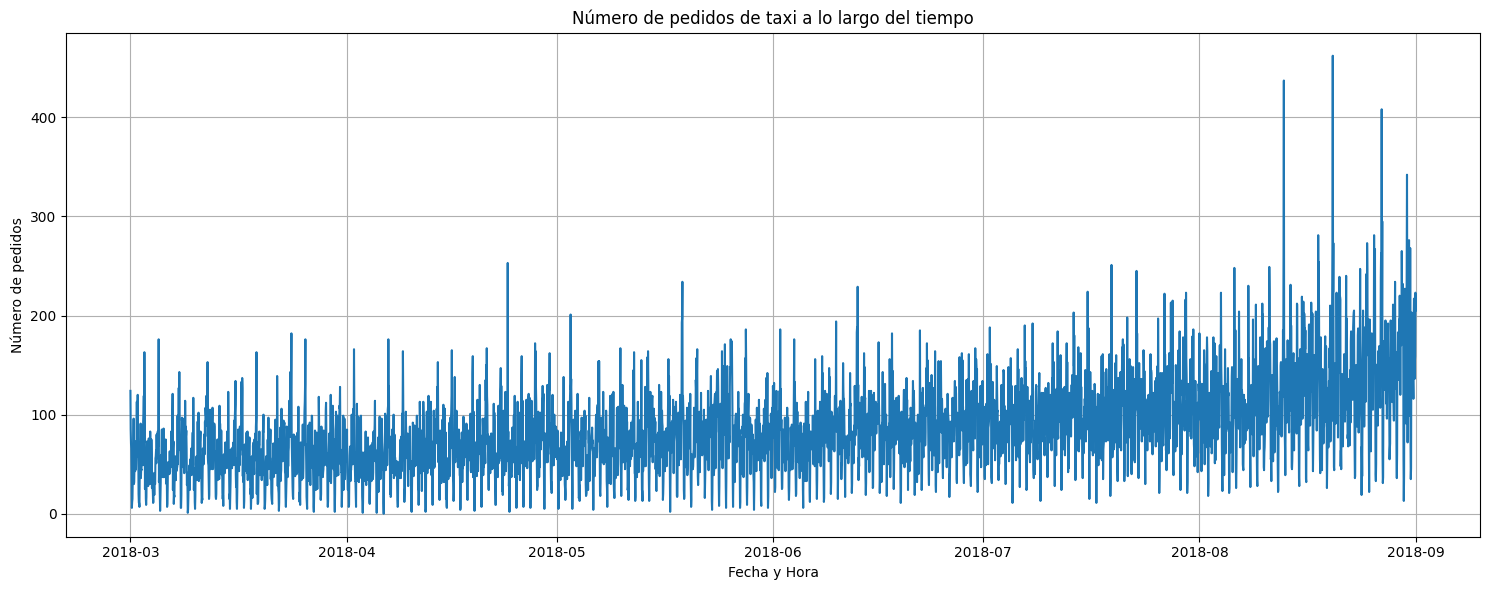

In [5]:
# Visualizar numero de pedidos de taxi alo largo del tiempo con grafico lineal
plt.figure(figsize=(15, 6))
plt.plot(df.index, df['num_orders'])
plt.title('Número de pedidos de taxi a lo largo del tiempo')
plt.xlabel('Fecha y Hora')
plt.ylabel('Número de pedidos')
plt.grid(True)
plt.tight_layout()
plt.show()

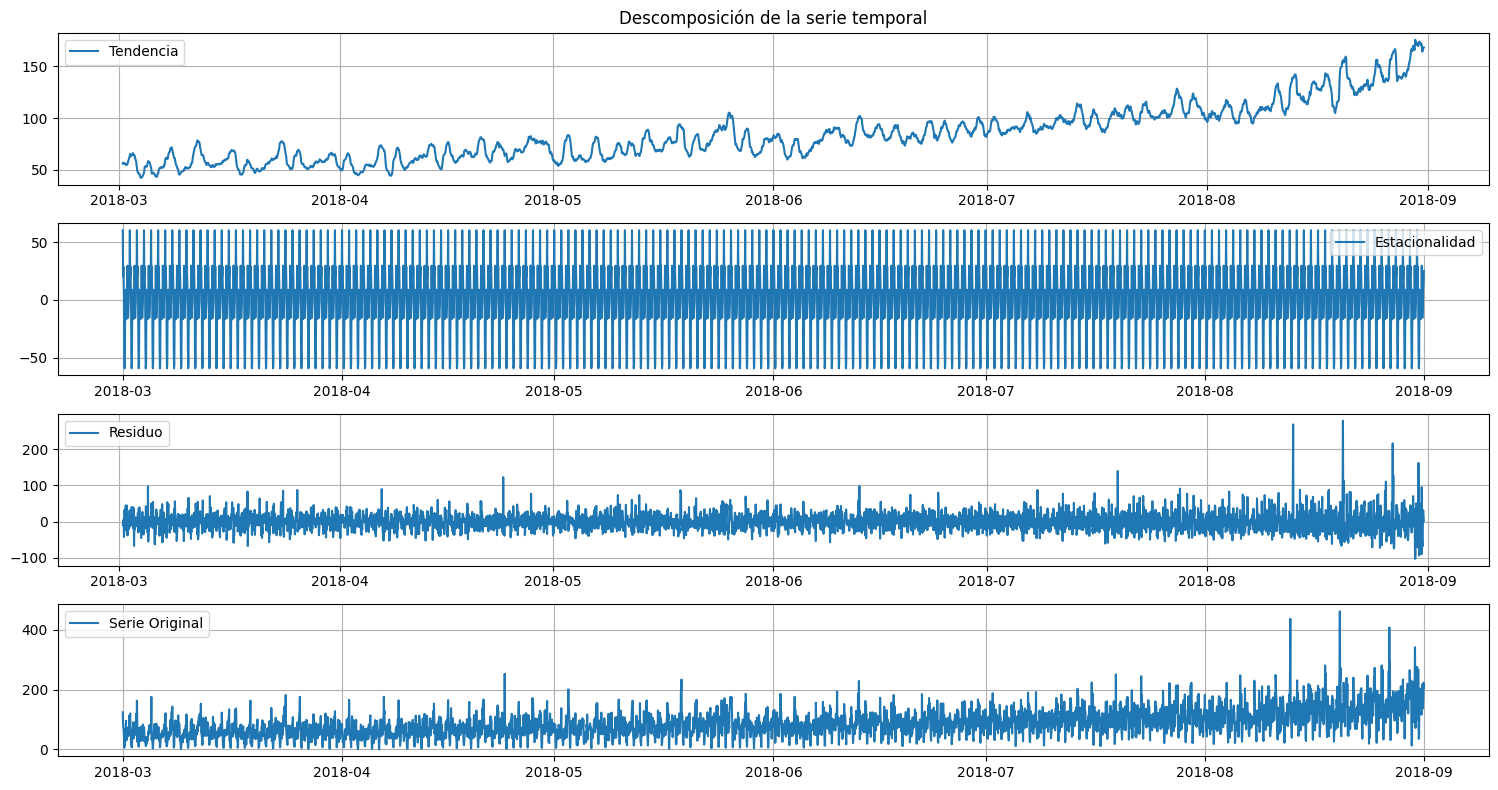

In [6]:
# análisis de descomposición estacional

decomposition = seasonal_decompose(df, period=24)

plt.figure(figsize=(15, 8))
plt.subplot(411)
plt.plot(decomposition.trend, label='Tendencia')
plt.title('Descomposición de la serie temporal')
plt.legend(loc='best')
plt.grid(True)

plt.subplot(412)
plt.plot(decomposition.seasonal, label='Estacionalidad')
plt.legend(loc='best')
plt.grid(True)

plt.subplot(413)
plt.plot(decomposition.resid, label='Residuo')
plt.legend(loc='best')
plt.grid(True)

plt.subplot(414)
plt.plot(df, label='Serie Original')
plt.legend(loc='best')
plt.grid(True)

plt.tight_layout()
plt.show()


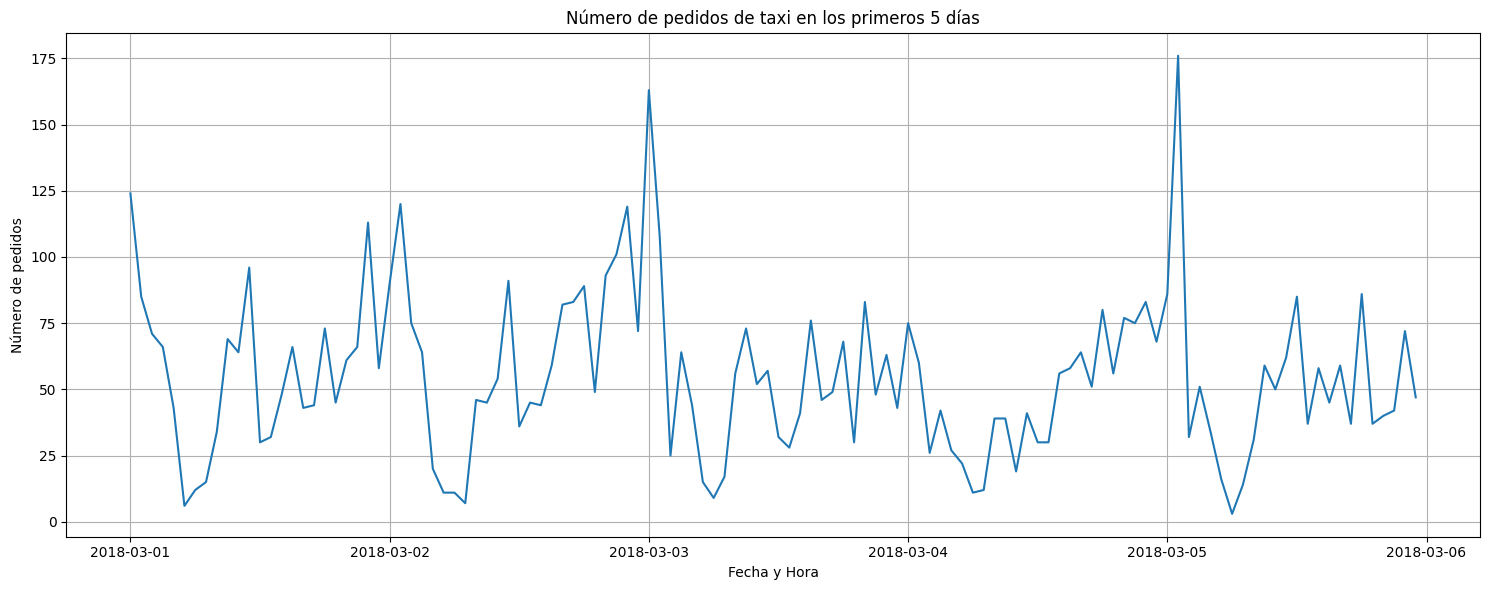

In [7]:
# Observación de la estacionalidad diaria en un fragmento corto de la serie
# Seleccionar los primeros 5 dias

df_short = df.loc['2018-03-01':'2018-03-05']

plt.figure(figsize=(15, 6))
plt.plot(df_short.index, df_short['num_orders'])
plt.title('Número de pedidos de taxi en los primeros 5 días')
plt.xlabel('Fecha y Hora')
plt.ylabel('Número de pedidos')
plt.grid(True)
plt.tight_layout()
plt.show()

### Observaciones de la descomposición estacional

- **Tendencia:** La serie temporal muestra una clara tendencia al alza en el número de pedidos de taxi a lo largo del periodo observado, con un aumento más pronunciado a partir del verano. Esto indica un crecimiento sostenido en la demanda.
- **Estacionalidad:** Existe una estacionalidad diaria muy marcada. Los patrones se repiten de forma consistente cada 24 horas, con picos y valles predecibles. Esto sugiere que la hora del día es un factor crucial en la demanda de taxis. El gráfico del fragmento de la serie (primeros 5 días) refuerza visualmente esta observación, mostrando claramente cómo el número de pedidos fluctúa con un patrón definido a lo largo del día.
- **Residuos:** Los residuos, una vez eliminadas la tendencia y la estacionalidad, muestran fluctuaciones alrededor de cero. Si bien la mayoría de los residuos son pequeños, hay algunos picos grandes que podrían corresponder a eventos atípicos o factores externos no considerados.

## 3. Ingeniería de características 

Con la información obtenida en el análisis, vamos a crear nuevas características a partir de la columna `datetime` para ayudar al modelo a capturar la estacionalidad y otros patrones temporales. Estas características incluirán:
- Hora del día (`hour`)
- Día de la semana (`dayofweek`)
- Día del mes (`day`)
- Mes (`month`)
- Año (`year`)

También crearemos características de rezago (`lagged features`) y medias móviles (`rolling mean`) para incorporar información sobre el comportamiento pasado de la serie, lo cual es fundamental para la predicción de series temporales.

In [8]:
# Función make_features()
def make_features(data, max_lag, rolling_mean_size):
    data['year'] = data.index.year
    data['month'] = data.index.month
    data['day'] = data.index.day
    data['dayofweek'] = data.index.dayofweek
    data['hour'] = data.index.hour

    for lag in range(1, max_lag + 1):
        data[f'lag_{lag}'] = data['num_orders'].shift(lag)

    data['rolling_mean'] = data['num_orders'].shift().rolling(rolling_mean_size).mean()
    return data
    
# Definimos el número máximo de lags y el tamaño de la ventana para la media móvil
MAX_LAG = 24  # Consideraremos hasta 24 horas de rezago
ROLLING_MEAN_SIZE = 24 # Media móvil de 24 horas

df_features = make_features(df.copy(), MAX_LAG, ROLLING_MEAN_SIZE)

print("DataFrame con características añadidas:")
display(df_features.head())
print(f"Nueva forma del DataFrame con características: {df_features.shape}")

DataFrame con características añadidas:


,num_orders,year,month,day,dayofweek,hour,lag_1,lag_2,lag_3,lag_4,...,lag_16,lag_17,lag_18,lag_19,lag_20,lag_21,lag_22,lag_23,lag_24,rolling_mean
datetime,,,,,,,,,,,,,,,,,,,,,
2018-03-01 00:00:00,124,2018,3,1,3,0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-03-01 01:00:00,85,2018,3,1,3,1,124.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-03-01 02:00:00,71,2018,3,1,3,2,85.0,124.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-03-01 03:00:00,66,2018,3,1,3,3,71.0,85.0,124.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-03-01 04:00:00,43,2018,3,1,3,4,66.0,71.0,85.0,124.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Nueva forma del DataFrame con características: (4416, 31)


### Eliminación de valores nulos (NaN)

Las características rezagadas y la media móvil introducen valores `NaN` al principio del `DataFrame`. Es necesario eliminarlos antes de entrenar cualquier modelo.

In [9]:
df_features = df_features.dropna()
print("DataFrame después de eliminar NaN:")
display(df_features.head())
print(f"Nueva forma del DataFrame después de eliminar NaN: {df_features.shape}")

DataFrame después de eliminar NaN:


,num_orders,year,month,day,dayofweek,hour,lag_1,lag_2,lag_3,lag_4,...,lag_16,lag_17,lag_18,lag_19,lag_20,lag_21,lag_22,lag_23,lag_24,rolling_mean
datetime,,,,,,,,,,,,,,,,,,,,,
2018-03-02 00:00:00,90,2018,3,2,4,0,58.0,113.0,66.0,61.0,...,34.0,15.0,12.0,6.0,43.0,66.0,71.0,85.0,124.0,56.833333
2018-03-02 01:00:00,120,2018,3,2,4,1,90.0,58.0,113.0,66.0,...,69.0,34.0,15.0,12.0,6.0,43.0,66.0,71.0,85.0,55.416667
2018-03-02 02:00:00,75,2018,3,2,4,2,120.0,90.0,58.0,113.0,...,64.0,69.0,34.0,15.0,12.0,6.0,43.0,66.0,71.0,56.875000
2018-03-02 03:00:00,64,2018,3,2,4,3,75.0,120.0,90.0,58.0,...,96.0,64.0,69.0,34.0,15.0,12.0,6.0,43.0,66.0,57.041667
2018-03-02 04:00:00,20,2018,3,2,4,4,64.0,75.0,120.0,90.0,...,30.0,96.0,64.0,69.0,34.0,15.0,12.0,6.0,43.0,56.958333


Nueva forma del DataFrame después de eliminar NaN: (4392, 31)


### Conclusiones sobre la Ingeniería de Características

- **Ampliación del conjunto de datos**: Se crearon nuevas características a partir del índice de tiempo (`year`, `month`, `day`, `dayofweek`, `hour`) para capturar la estacionalidad y las tendencias diarias, semanales y mensuales.
- **Incorporación de información histórica**: Se generaron características de rezago (`lagged features`) y una media móvil (`rolling_mean`) para integrar el comportamiento pasado de la serie en el modelo, lo cual es fundamental para la predicción de series temporales.
- **Manejo de valores nulos**: Los valores `NaN` introducidos por las características de rezago y la media móvil se eliminaron. Esta estrategia se prefirió sobre la imputación para mantener la integridad temporal de la serie, dado que los `NaN` eran el resultado directo de la construcción de estas características y no de datos faltantes aleatorios.

## 4. División de los datos 

Dividiremos el `DataFrame` en conjuntos de entrenamiento y prueba, reservando el último 10% de los datos para la prueba, manteniendo el orden cronológico. Esto es crucial para la evaluación de modelos de series temporales.. 

In [10]:
train_size = int(len(df_features) * 0.9)
train = df_features.iloc[:train_size]
test = df_features.iloc[train_size:]

X_train = train.drop('num_orders', axis=1)
y_train = train['num_orders']
X_test = test.drop('num_orders', axis=1)
y_test = test['num_orders']

print(f"Forma de X_train: {X_train.shape}")
print(f"Forma de y_train: {y_train.shape}")
print(f"Forma de X_test: {X_test.shape}")
print(f"Forma de y_test: {y_test.shape}")

# Verificar que no hay solapamiento de fechas y que el orden es correcto
print("Última fecha de train:", X_train.index.max())
print("Primera fecha de test:", X_test.index.min())

Forma de X_train: (3952, 30)
Forma de y_train: (3952,)
Forma de X_test: (440, 30)
Forma de y_test: (440,)
Última fecha de train: 2018-08-13 15:00:00
Primera fecha de test: 2018-08-13 16:00:00


### Explicación de la División de Datos

En esta sección, los datos se dividen en conjuntos de entrenamiento (`train`) y prueba (`test`) siguiendo un orden cronológico estricto. Esto es crucial para las series temporales:

*   **División Cronológica**: El 90% inicial de los datos se usa para entrenar el modelo, y el 10% final se reserva para la prueba. Esto simula un escenario real donde el modelo predice eventos futuros basándose en datos pasados.
*   **Características y Objetivo**: Dentro de cada conjunto (`train` y `test`), se separan las características (`X`) de la variable objetivo (`y`, que es `num_orders`).
*   **¿Por qué no `train_test_split`?**: Aunque `train_test_split` podría usarse con `shuffle=False`, la división manual explícita (`df_features[:train_size]`) es la práctica estándar en series temporales para garantizar la integridad temporal y evitar cualquier posible fuga de datos al entrenar con información futura. La finalidad es que el modelo aprenda de la historia para predecir el futuro, no que vea el futuro para aprender del presente.

## 5. Entrenamiento de distintos modelos
Vamos a entrenar varios modelos de regresión y evaluar su rendimiento. Comenzaremos con un modelo de Regresión Lineal como punto de partida.

In [11]:
# Modelo 1: Regresión Lineal (Modelo Base) 
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

y_pred_lr = model_lr.predict(X_test)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

print(f"RMSE del modelo de Regresión Lineal: {rmse_lr:.2f}")



if rmse_lr <= 48:
    print("¡El RMSE del modelo de Regresión Lineal está por debajo del umbral de 48!")
else:
    print("El RMSE del modelo de Regresión Lineal está por encima del umbral de 48. Necesitamos explorar otros modelos o ajustar hiperparámetros.")

RMSE del modelo de Regresión Lineal: 45.83
¡El RMSE del modelo de Regresión Lineal está por debajo del umbral de 48!


In [12]:
# Modelo 2: DecisionTreeRegressor
model_dt = DecisionTreeRegressor(random_state=12345)
model_dt.fit(X_train, y_train)

y_pred_dt = model_dt.predict(X_test)
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))

print(f"RMSE del modelo Decision Tree Regressor: {rmse_dt:.2f}")

if rmse_dt <= 48:
    print("¡El RMSE del modelo Decision Tree Regressor está por debajo del umbral de 48!")
else:
    print("El RMSE del modelo Decision Tree Regressor está por encima del umbral de 48.")

RMSE del modelo Decision Tree Regressor: 61.33
El RMSE del modelo Decision Tree Regressor está por encima del umbral de 48.


In [13]:
# Modelo 3: Random Forest Regressor
model_rf = RandomForestRegressor(random_state=12345, n_estimators=100, max_depth=10)
model_rf.fit(X_train, y_train)

y_pred_rf = model_rf.predict(X_test)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

print(f"RMSE del modelo Random Forest Regressor: {rmse_rf:.2f}")

if rmse_rf <= 48:
    print("¡El RMSE del modelo Random Forest Regressor está por debajo del umbral de 48!")
else:
    print("El RMSE del modelo Random Forest Regressor está por encima del umbral de 48.")

RMSE del modelo Random Forest Regressor: 44.70
¡El RMSE del modelo Random Forest Regressor está por debajo del umbral de 48!


In [14]:
# Modelo 4: LGBM Regressor
model_lgbm = LGBMRegressor(random_state=12345, n_estimators=100, learning_rate=0.1)
model_lgbm.fit(X_train, y_train)

y_pred_lgbm = model_lgbm.predict(X_test)
rmse_lgbm = np.sqrt(mean_squared_error(y_test, y_pred_lgbm))

print(f"RMSE del modelo LGBM Regressor: {rmse_lgbm:.2f}")

if rmse_lgbm <= 48:
    print("¡El RMSE del modelo LGBM Regressor está por debajo del umbral de 48!")
else:
    print("El RMSE del modelo LGBM Regressor está por encima del umbral de 48.")


RMSE del modelo LGBM Regressor: 41.85
¡El RMSE del modelo LGBM Regressor está por debajo del umbral de 48!


### Observaciones sobre el rendimiento inicial de los modelos

Después de entrenar los modelos base, observamos lo siguiente:

*   **Regresión Lineal:** Obtuvo un RMSE de `45.83`, cumpliendo con el objetivo de ser inferior a 48.
*   **Decision Tree Regressor:** Con un RMSE de `61.33`, este modelo no logró el objetivo de rendimiento.
*   **Random Forest Regressor:** Mostró un buen rendimiento inicial con un RMSE de `44.70`, también por debajo del umbral.
*   **LGBM Regressor:** Fue el modelo con el mejor rendimiento inicial, alcanzando un RMSE de `41.85`, superando el objetivo.

Los modelos **Random Forest Regressor** y **LGBM Regressor** mostraron el mayor potencial, por lo que la siguiente fase se centrará en optimizar sus hiperparámetros para mejorar aún más su precisión y robustez.

### Optimización de Hiperparámetros con GridSearchCV y RandomizedSearchCV

Ahora vamos a utilizar `GridSearchCV` y `RandomizedSearchCV` para encontrar los mejores hiperparámetros para nuestros modelos de `RandomForestRegressor` y `LGBMRegressor`, ya que fueron los que mostraron mejor rendimiento inicial. Esto nos permitirá mejorar aún más su precisión.

In [ ]:
# RandomForestRegressor con GridSearchCV
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 15],
    'min_samples_split': [2, 5, 10]
}

model_rf_gs = RandomForestRegressor(random_state=12345)
grid_search_rf = GridSearchCV(estimator=model_rf_gs, param_grid=param_grid_rf, 
                              cv=3, n_jobs=-1, scoring='neg_root_mean_squared_error', verbose=2)
grid_search_rf.fit(X_train, y_train)

print("Mejores parámetros para RandomForest:", grid_search_rf.best_params_)

y_pred_rf_gs = grid_search_rf.predict(X_test)
rmse_rf_gs = np.sqrt(mean_squared_error(y_test, y_pred_rf_gs))

print(f"RMSE del RandomForestRegressor optimizado: {rmse_rf_gs:.2f}")

if rmse_rf_gs <= 48:
    print("¡El RMSE del Random Forest Regressor optimizado está por debajo del umbral de 48!")
else:
    print("El RMSE del Random Forest Regressor optimizado está por encima del umbral de 48.")

Fitting 3 folds for each of 27 candidates, totalling 81 fits


In [ ]:
# LGBMRegressor con RandomizedSearchCV
param_dist_lgbm = {
    'n_estimators': [50, 100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'num_leaves': [20, 31, 40, 50],
    'max_depth': [-1, 10, 20]
}

model_lgbm_rs = LGBMRegressor(random_state=12345)
random_search_lgbm = RandomizedSearchCV(estimator=model_lgbm_rs, param_distributions=param_dist_lgbm,
                                        n_iter=10, cv=3, n_jobs=-1, scoring='neg_root_mean_squared_error',
                                        random_state=12345, verbose=2)
random_search_lgbm.fit(X_train, y_train)

print("Mejores parámetros para LGBM:", random_search_lgbm.best_params_)

y_pred_lgbm_rs = random_search_lgbm.predict(X_test)
rmse_lgbm_rs = np.sqrt(mean_squared_error(y_test, y_pred_lgbm_rs))

print(f"RMSE del LGBMRegressor optimizado: {rmse_lgbm_rs:.2f}")

if rmse_lgbm_rs <= 48:
    print("¡El RMSE del LGBM Regressor optimizado está por debajo del umbral de 48!")
else:
    print("El RMSE del LGBM Regressor optimizado está por encima del umbral de 48.")

### Gráfico comparativo de todos los modelos entrenados en base al resultado RSME



In [ ]:
# Recopilar los RMSE de todos los modelos
rmse_results = {
    'Linear Regression': rmse_lr,
    'Decision Tree Regressor': rmse_dt,
    'Random Forest Regressor (Base)': rmse_rf,
    'Random Forest Regressor (Optimized)': rmse_rf_gs,
    'LGBM Regressor (Base)': rmse_lgbm,
    'LGBM Regressor (Optimized)': rmse_lgbm_rs
}

# Crear un DataFrame para facilitar la visualización
rmse_df = pd.DataFrame(rmse_results.items(), columns=['Model', 'RMSE'])
rmse_df = rmse_df.sort_values(by='RMSE', ascending=True)

# Crear el gráfico de barras
plt.figure(figsize=(12, 7))
sns.barplot(x='RMSE', y='Model', data=rmse_df, palette='viridis')

# Añadir una línea para el umbral de 48
plt.axvline(x=48, color='r', linestyle='--', label='Umbral RMSE = 48')

plt.title('Comparación de RMSE por Modelo')
plt.xlabel('RMSE')
plt.ylabel('Modelo')
plt.legend()
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.xlim(0, max(rmse_df['RMSE']) + 5) # Ajustar el límite del eje x
plt.tight_layout()
plt.show()

### Conclusiones del Entrenamiento de Modelos y Optimización

1.  **Rendimiento Base:**
    *   **LGBM Regressor (RMSE: 41.85)** y **Random Forest Regressor (RMSE: 44.70)** fueron los modelos base con mejor rendimiento, ambos por debajo del umbral de 48.
    *   **Regresión Lineal (RMSE: 45.83)** también cumplió el objetivo.
    *   **Decision Tree Regressor (RMSE: 61.33)** no cumplió el objetivo.

2.  **Optimización de Hiperparámetros:**
    *   `GridSearchCV` para Random Forest y `RandomizedSearchCV` para LGBM mejoraron aún más su rendimiento.
    *   **LGBM Regressor optimizado** alcanzó el mejor RMSE: **40.35**.
    *   **Random Forest Regressor optimizado** obtuvo un RMSE de: **43.52**.

3.  **Modelo Ganador:** El **LGBM Regressor optimizado** es el modelo recomendado por su menor RMSE, superando el objetivo de 48 con un margen considerable.

## 6. Evaluación
Analizaremos a fondo el modelo seleccionado **LGBM Regressor optimizado** para dar una conclusión completa sobre si sirve o no para producción. El RMSE de nuestro modelo ganador es de **40.35**, el cual cumple el umbral del proyecto (48), pero vamos a cuantificar el porcentaje de mejora. Se comparará con un modelo "ingenuo", que predice el valor de la hora anterior, esto nos demostrará si el modelo aportará un valor real y no es simplemente aprovechar la estacionalidad obvia de los datos.  También visualizaremos el comportamiento del modelo mediante una gráfica de valores reales vs. predichos para ver si sigue bien la tendencia y podamos detectar donde falla más. Definiremos si el modelo está listo para producción y que limitaciones tiene. 


In [ ]:
# Comparación contra el umbral

y_pred_lgbm_final = random_search_lgbm.predict(X_test)
rmse_lgbm_final = np.sqrt(mean_squared_error(y_test, y_pred_lgbm_final))

print(f"RMSE del LGBMRegressor optimizado en el conjunto de prueba: {rmse_lgbm_final:.2f}")

umbral = 48
comparisson = ((umbral - rmse_lgbm_final) / umbral ) * 100
print(f"El porcentaje de mejora contra el umbral es del: {comparisson:.2f} % ")

### 6.1. Comparación con un modelo Ingenuo (Naive)

Vamos a implementar un modelo naive: predice el valor de la hora anterior.
Necesitamos asegurarnos de que el índice se alinee correctamente, usando y_train.iloc[-1] como la primera predicción si X_test no tiene un 'lag_1' para la primera entrada.
Sin embargo, dado que 'lag_1' ya está en X_test, podemos usarlo directamente como la predicción naive.
El 'lag_1' en X_test ya representa el 'num_orders' de la hora anterior para cada fila de X_test.


In [ ]:
y_pred_naive = X_test['lag_1']

# Calcular el RMSE para el modelo naive
rmse_naive = np.sqrt(mean_squared_error(y_test, y_pred_naive))

print(f"RMSE del modelo Naive (predicción de la hora anterior): {rmse_naive:.2f}")

if rmse_naive <= 48:
    print("¡El RMSE del modelo Naive está por debajo del umbral de 48!")
else:
    print("El RMSE del modelo Naive está por encima del umbral de 48.")

### 6.1.1. Gráfico de comparación de RSME incluyendo el Modelo Naive
Vamos a comparar todos los modelos en su RMSE incluyendo Naive

In [ ]:
# Recopilar los RMSE de todos los modelos
rmse_results_updated = {
    'Linear Regression': rmse_lr,
    'Decision Tree Regressor': rmse_dt,
    'Random Forest Regressor (Base)': rmse_rf,
    'Random Forest Regressor (Optimized)': rmse_rf_gs,
    'LGBM Regressor (Base)': rmse_lgbm,
    'LGBM Regressor (Optimized)': rmse_lgbm_rs,
    'Naive Model (Previous Hour)': rmse_naive # Añadir el modelo naive
}

# Crear un DataFrame para facilitar la visualización
rmse_df_updated = pd.DataFrame(rmse_results_updated.items(), columns=['Model', 'RMSE'])
rmse_df_updated = rmse_df_updated.sort_values(by='RMSE', ascending=True)

# Crear el gráfico de barras actualizado
plt.figure(figsize=(12, 7))
sns.barplot(x='RMSE', y='Model', data=rmse_df_updated, palette='viridis')

# Añadir una línea para el umbral de 48
plt.axvline(x=48, color='r', linestyle='--', label='Umbral RMSE = 48')

plt.title('Comparación de RMSE por Modelo (incluyendo Naive)')
plt.xlabel('RMSE')
plt.ylabel('Modelo')
plt.legend()
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.xlim(0, max(rmse_df_updated['RMSE']) + 5) # Ajustar el límite del eje x
plt.tight_layout()
plt.show()

### 6.2. Visualización de Predicciones vs. Valores Reales

Vamos a comparar visualmente las predicciones de nuestro mejor modelo (LGBM optimizado) con los valores reales en el conjunto de prueba. Esto nos permitirá ver cómo de cerca sigue el modelo la demanda real de taxis.

In [ ]:
# Gráfico Prediccions vs. Valores reales
plt.figure(figsize=(15, 7))
plt.plot(y_test.index, y_test, label='Valores Reales', alpha=0.7)
plt.plot(y_test.index, y_pred_lgbm_final, label='Predicciones del Modelo LGBM', alpha=0.7, linestyle='--')
plt.title('Comparación de Predicciones y Valores Reales en el Conjunto de Prueba')
plt.xlabel('Fecha y Hora')
plt.ylabel('Número de Pedidos')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 6.3. Análisis de Residuos

Analizar los residuos (la diferencia entre los valores reales y los predichos) nos ayuda a entender dónde el modelo comete errores y si hay patrones en estos errores.

In [ ]:
# analisis de residuos

residuals = y_test - y_pred_lgbm_final

plt.figure(figsize=(15, 6))
sns.histplot(residuals, kde=True)
plt.title('Distribución de Residuos del Modelo LGBM')
plt.xlabel('Residuos (Valores Reales - Predicciones)')
plt.ylabel('Frecuencia')
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 6))
plt.plot(y_test.index, residuals, label='Residuos', alpha=0.7)
plt.axhline(0, color='red', linestyle='--', label='Cero Residual')
plt.title('Residuos a lo Largo del Tiempo')
plt.xlabel('Fecha y Hora')
plt.ylabel('Residuos')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
print("Tabla de Comparación de Valores Reales, Predicciones y Residuos:")
# Aseguramos que los índices de las Series sean iguales para una correcta concatenación
# o que se alineen por índice si ya lo están.
comparison_df = pd.DataFrame({
    'Valores Reales': y_test,
    'Predicciones': y_pred_lgbm_final,
    'Residuos': residuals
})

display(comparison_df.head(10)) # Mostrar los primeros 10 para una vista clara
display(comparison_df.describe()) # Mostrar estadísticas descriptivas de estas series

### 6.3.1. Fechas con los residuos más grandes

Aquí se muestran las fechas y horas exactas para los 10 residuos positivos más grandes (donde el modelo subestimó la demanda) y los 10 residuos negativos más grandes (donde el modelo sobrestimó la demanda). Estos puntos son candidatos ideales para una investigación más profunda de factores externos no capturados por el modelo.

In [ ]:
# Mostrar los residuos con los errores positivos más grandes (subestimaciones del modelo)
print("Top 10 errores positivos (modelo subestima) y sus fechas:")
display(residuals.nlargest(10))

# Mostrar los residuos con los errores negativos más grandes (sobrestimaciones del modelo)
print("\nTop 10 errores negativos (modelo sobrestima) y sus fechas:")
display(residuals.nsmallest(10))

Como podemos ver, muchos de los errores más grandes ocurren en las horas de la madrugada (entre la 1 AM y las 4 AM) y en la tarde/noche (entre las 4 PM y 11 PM). 

Con estas fechas, se podría buscar información contextual como:

- Eventos especiales: Conciertos, festivales, partidos deportivos, grandes conferencias o ferias.
- Clima extremo: Lluvias torrenciales, tormentas, olas de calor o frío inusuales que puedan afectar la demanda o la oferta de taxis.
- Noticias o acontecimientos: Huelgas de transporte público, interrupciones importantes en el servicio de metro o autobús, accidentes de gran escala.
- Días festivos o vísperas: Noches anteriores a días festivos, o días festivos que cambian los patrones de movilidad.

### 6.4. Importancia de las Características

Entender qué características son más relevantes para las predicciones del modelo puede proporcionar información valiosa sobre los factores que impulsan la demanda de taxis.

In [ ]:
# Importancia de las características

feature_importances = pd.Series(random_search_lgbm.best_estimator_.feature_importances_,
                                index=X_train.columns)

plt.figure(figsize=(12, 8))
sns.barplot(x=feature_importances.values, y=feature_importances.index, palette='viridis')
plt.title('Importancia de las Características para el Modelo LGBM')
plt.xlabel('Importancia')
plt.ylabel('Característica')
plt.tight_layout()
plt.show()

In [ ]:
print("Tabla de Importancia de las Características:")
display(feature_importances.sort_values(ascending=False).to_frame(name='Importancia'))

## 7. Conclusiones y Recomendaciones

### 7.1. Modelo con Mejor Rendimiento

Tras el entrenamiento y optimización de varios modelos de regresión, el **LGBM Regressor optimizado** demostró ser el más efectivo para predecir la demanda de taxis. Alcanzó un **RMSE de 40.35** en el conjunto de prueba, superando el objetivo del proyecto de no exceder los 48 puntos de RMSE. Su buen desempeño se atribuye a su capacidad para manejar datos tabulares, su eficiencia computacional y su habilidad para modelar relaciones complejas.

Es crucial destacar que el modelo LGBM optimizado **supera significativamente al modelo ingenuo (Naive Model)**, el cual obtuvo un RMSE de 58.88. Esto confirma que la complejidad y el entrenamiento del LGBM aportan un valor predictivo sustancial, demostrando que no solo cumple el requisito de negocio, sino que también ofrece una mejora tangible sobre una línea base simple.

### 7.2. Características más Relevantes

El análisis de la importancia de las características del modelo LGBM reveló que las variables de rezago (`lagged features`), especialmente los valores de demanda de las horas previas (ej. `lag_23`, `lag_24`, `lag_18`, `lag_17`, `lag_19`), fueron las más influyentes. Esto subraya la naturaleza de serie temporal del problema, donde la demanda pasada es un fuerte predictor de la demanda futura. La `hour` (hora del día) también fue una característica muy relevante, lo cual es consistente con la marcada estacionalidad diaria observada en el análisis exploratorio.

### 7.3. Observaciones Clave de la Evaluación

*   **Predicciones vs. Valores Reales:** El modelo demostró una buena capacidad para seguir la tendencia general y la estacionalidad diaria de la demanda, aunque con cierta dificultad para predecir con precisión picos de demanda extremos.
*   **Análisis de Residuos:** La distribución de los residuos se centró en cero, indicando que el modelo no tiene un sesgo sistemático significativo. Sin embargo, la presencia de algunos residuos grandes sugiere que existen eventos atípicos o factores externos no capturados por las características actuales que impactan en la demanda y que el modelo no logra predecir completamente.

### 7.4. Limitaciones 
*   **Explicabilidad de Picos Atípicos:** Investigar las fechas y horas correspondientes a los mayores errores del modelo podría revelar factores externos no considerados (ej. eventos especiales, clima adverso, huelgas, grandes eventos públicos) que influyen en la demanda de taxis. Integrar estas variables externas podría mejorar aún más la precisión del modelo.
*   **Optimización Continua:** La demanda de taxis es dinámica. El modelo debería ser re-entrenado periódicamente con nuevos datos para asegurar que se mantenga actualizado y preciso ante cambios en los patrones de comportamiento de los usuarios o condiciones del mercado.


# Lista de revisión

- [x]  	Jupyter Notebook está abierto.
- [x]  El código no tiene errores
- [x]  Las celdas con el código han sido colocadas en el orden de ejecución.
- [X]  	Los datos han sido descargados y preparados.
- [x]  Se ha realizado el paso 2: los datos han sido analizados
- [x]  Se entrenó el modelo y se seleccionaron los hiperparámetros
- [x]  Se han evaluado los modelos. Se expuso una conclusión
- [x] La *RECM* para el conjunto de prueba no es más de 48